# 40. Does a specialist beat the flat model inside the hard group? (validation only)

**Question.** Notebook 39 fixed the hard group: Cross Court Flight, Lift, Block, Drop Shot, Push Shot and Flat Shot (`configs/hard_group.json`). Before a coarse head is built, this notebook
asks the part that decides whether the hierarchy can work at all: **given a clip that belongs to the group, does a model trained on group clips only separate its six members better than the
ordinary 18 way `both` model does?**

| arm | what is trained | how it is scored on the group validation clips |
|---|---|---|
| `flat` | the 18 way `both` model (notebook 36 recipe, class balanced sampler, advanced augmentation) | its outputs restricted to the six group classes, so it is not penalised for answering with an outsider |
| `specialist` | a 6 way `both` model on group clips only, same recipe, **schedule stretched to match the number of optimiser steps** of `flat` | its six outputs |
| `specialist_plain` | as `specialist`, with the unchanged recipe (60 epochs, step 10) | its six outputs (sensitivity row) |

The specialist sees about a third of the clips per epoch (the sampler draws about 2,474 clips against about 7,948), so the unchanged schedule gives it about a third of the optimiser steps. `specialist` therefore
multiplies the number of epochs, the patience and the learning rate step by the same factor (`SCALE`, computed below), which keeps the number of optimiser steps equal. `specialist_plain` shows what the
unchanged recipe does.

Scoring is on the same clips for all arms: the validation clips of the six group classes. The metrics are accuracy and mean class accuracy (MCA) over those six classes.

**Rule, fixed before running.** Validation only, tuning seeds 77 and 88, checkpoints chosen on the composite (mean of validation top1 and MCA of the arm's own task). The specialist (the step matched
arm) passes if

1. its mean group accuracy is at least **2.0 points** above `flat`,
2. its mean group MCA is **not more than 1.0 point below** `flat`, and
3. it is above `flat` in **both** seeds.

Two points of group accuracy is about +0.7 top1 overall (about one third of all clips pass through the group), roughly the seed to seed noise of the full model, so a smaller gain could not be told apart
from chance. The bootstrap interval over clips is reported next to the rule and is not part of it. `specialist_plain` is a sensitivity row and cannot pass the rule by itself.

If the rule is not passed, the coarse head is not built and this is recorded as a negative result.

The test set is never loaded: test rows are removed from the manifest before any dataset is built. Logs go to `BadmintonPoseAnalysis/experiments/model5_hierarchy`. 6 runs (3 arms, 2 seeds).

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/model5_hierarchy"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT = f"{OUTPUTS}/experiments/model5_hierarchy/specialist"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]                        # tuning seeds; the reporting seeds 42, 123, 7 are not used here
SELECT_METRIC = "composite"
NORMALISATION, USE_COURT, POLICY = "body", True, "advanced"
NUM_WORKERS, EVAL_WORKERS = 20, 8
N_BOOT = 2000
MIN_GAIN, MAX_MCA_DROP = 0.02, 0.01
ARMS = {"flat": dict(kind="flat"), "specialist": dict(kind="specialist", stretch=True), "specialist_plain": dict(kind="specialist", stretch=False)}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
TARGET = RECIPE["target_per_class"]
with open(f"{REPO}/configs/hard_group.json") as f:
    HG = json.load(f)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest = manifest[manifest["split"] != "test"].reset_index(drop=True)          # the test set is not loaded in this notebook
assert "test" not in set(manifest["split"])

class_names = sorted(manifest["class_name"].unique())
assert class_names == HG["class_names"], "class list differs from the one used to fix the group"
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[-1] for c in class_names]
GROUP_FULL = HG["group_class_names"]
GROUP_IDS = np.array(HG["group_ids"])
GROUP_SHORT = [short[k] for k in GROUP_IDS]
group_to_id = {c: i for i, c in enumerate(GROUP_FULL)}
G_INDEX = np.full(K, -1)
G_INDEX[GROUP_IDS] = np.arange(len(GROUP_IDS))
SHARE = HG["top1_per_point_within_group"]            # top1 points per point of group accuracy (share of clips passing through the group)

manifest_group = manifest[manifest["class_name"].isin(GROUP_FULL)].reset_index(drop=True)
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
flat_draws = int(sum(max(n, TARGET) for n in train_counts))
spec_draws = int(sum(max(train_counts[c], TARGET) for c in GROUP_FULL))
SCALE = max(1, round(flat_draws / spec_draws))
IN_CH = tp.n_channels(USE_COURT)
print(f"group: {GROUP_SHORT}")
print(f"{K} classes, {len(manifest)} clips (train and val); group clips {len(manifest_group)}: " + str(manifest_group['split'].value_counts().to_dict()))
print(f"sampler draws per epoch: flat {flat_draws}, specialist {spec_draws}; schedule stretch for the step matched specialist: x{SCALE} "
      f"(epochs {RECIPE['num_epochs'] * SCALE}, lr step {RECIPE.get('step_size', 10) * SCALE}, patience {RECIPE.get('patience', 20) * SCALE})")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
group: ['Cross Court Flight', 'Lift', 'Block', 'Drop Shot', 'Push Shot', 'Flat Shot']
18 classes, 7028 clips (train and val); group clips 2500: {'train': 2221, 'val': 279}
sampler draws per epoch: flat 7948, specialist 2474; schedule stretch for the step matched specialist: x3 (epochs 180, lr step 30, patience 60)


## Smoke test

Run this cell alone first. It checks the loaders, that no test clip can reach a loader, the two model heads and the sampler sizes.

In [3]:
tr.seed_everything(0)
rows = []
for arm, spec in ARMS.items():
    mf, c2i = (manifest, class_to_id) if spec["kind"] == "flat" else (manifest_group, group_to_id)
    loaders = tp.build_loaders(mf, SEL_INTERP, c2i, (0, 1), "basic", seed=0, batch_size=RECIPE["batch_size"], num_workers=2, eval_workers=2,
                               splits=("train", "val"), target_per_class=TARGET)
    assert "test" not in loaders
    batch = next(iter(loaders["train"]))
    assert batch["keypoints"].shape[1:] == (2, 30, 17, 3), batch["keypoints"].shape
    n_out = len(c2i)
    assert int(batch["label"].max()) < n_out
    model = tp.PersonsSTGCN(IN_CH, n_out, 2).to(device)
    logits = tp.make_forward(USE_COURT)(model, batch, device)
    assert logits.shape == (len(batch["label"]), n_out)
    rows.append({"arm": arm, "outputs": n_out, "train clips": len(loaders["train"].dataset), "val clips": len(loaders["val"].dataset),
                 "clips drawn per epoch": len(list(loaders["train"].sampler)), "parameters": sum(p.numel() for p in model.parameters())})
    del model, loaders
smoke = pd.DataFrame(rows)
print(smoke.to_string(index=False))
assert smoke.loc[smoke["arm"] == "flat", "clips drawn per epoch"].iloc[0] == flat_draws
assert smoke.loc[smoke["arm"] == "specialist", "clips drawn per epoch"].iloc[0] == spec_draws
assert smoke.loc[smoke["arm"] == "specialist", "val clips"].iloc[0] == int((manifest_group["split"] == "val").sum())
print("smoke test passed")

             arm  outputs  train clips  val clips  clips drawn per epoch  parameters
            flat       18         6247        781                   7948     3032891
      specialist        6         2221        279                   2474     3026735
specialist_plain        6         2221        279                   2474     3026735
smoke test passed


## Training

`group_metrics` scores every arm on the same clips: the validation clips of the group classes. For `flat` the 18 probabilities are cut to the six group columns before the argmax, so the model is only
asked which member it is. The unrestricted accuracy of `flat` on the same clips (answers outside the group count as wrong) is kept as a reference.

In [4]:
def group_metrics(kind, labels, probs, filepaths):
    if kind == "flat":
        mask = np.isin(labels, GROUP_IDS)
        lab = G_INDEX[labels[mask]]
        restricted = probs[mask][:, GROUP_IDS].argmax(1)
        unrestricted_ok = probs[mask].argmax(1) == labels[mask]
        files = np.asarray(filepaths)[mask]
    else:
        lab, restricted, files, unrestricted_ok = labels, probs.argmax(1), np.asarray(filepaths), None
    recalls = np.array([(restricted[lab == k] == k).mean() for k in range(len(GROUP_IDS))])
    out = {"group_acc": float((restricted == lab).mean()), "group_mca": float(recalls.mean()), "group_clips": int(len(lab))}
    out.update({f"rec_{n}": float(r) for n, r in zip(GROUP_SHORT, recalls)})
    if unrestricted_ok is not None:
        out["group_acc_unrestricted"] = float(unrestricted_ok.mean())
    return out, pd.DataFrame({"filepath": files, "label": lab, "pred": restricted})


def run_arm(arm, seed, results_path, done):
    if ((done["arm"] == arm) & (done["seed"] == seed)).any():
        print(f"skip {arm} seed {seed}")
        return done
    spec = ARMS[arm]
    kind = spec["kind"]
    mf, c2i, names = (manifest, class_to_id, class_names) if kind == "flat" else (manifest_group, group_to_id, GROUP_FULL)
    scale = SCALE if spec.get("stretch") else 1
    recipe = {**RECIPE, "num_epochs": RECIPE["num_epochs"] * scale, "patience": RECIPE.get("patience", 20) * scale,
              "step_size": RECIPE.get("step_size", 10) * scale}
    run_name = f"t40_{arm}_s{seed}"
    print(f"\n=== {run_name} (outputs {len(names)}, epochs up to {recipe['num_epochs']}, lr step {recipe['step_size']}) ===")
    tr.seed_everything(seed)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["hierarchy", "specialist_test", arm, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**recipe, "arm": arm, "kind": kind, "seed": seed, "select_metric": SELECT_METRIC, "policy": POLICY, "target_per_class": TARGET,
                  "n_outputs": len(names), "schedule_scale": scale, "group": GROUP_SHORT, "evaluated_splits": ["train", "val"], "split_sha256": split_hash})
    loaders = tp.build_loaders(mf, SEL_INTERP, c2i, (0, 1), POLICY, seed=seed, batch_size=recipe["batch_size"], num_workers=NUM_WORKERS,
                               eval_workers=EVAL_WORKERS, splits=("train", "val"), target_per_class=TARGET)
    model = tp.PersonsSTGCN(IN_CH, len(names), 2).to(device)
    forward = tp.make_forward(USE_COURT)
    optimizer = torch.optim.SGD(model.parameters(), lr=recipe["lr"], momentum=recipe["momentum"], weight_decay=recipe["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=recipe["step_size"], gamma=recipe["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=recipe["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device, task.get_logger(),
                                            num_epochs=recipe["num_epochs"], patience=recipe["patience"], select_metric=SELECT_METRIC,
                                            print_every=10, splits=("train", "val"))
    val = tr.evaluate(model, loaders["val"], forward, device)                    # the model holds the selected checkpoint
    gm, frame = group_metrics(kind, val["labels"], val["probs"], val["filepaths"])
    out_dir = f"{OUT}/{run_name}"
    os.makedirs(out_dir, exist_ok=True)
    frame.to_csv(f"{out_dir}/{run_name}_group_val.csv", index=False)
    metrics = tr.report_run(task, model, forward, loaders, names, device, history, best_epoch, out_dir=out_dir, run_name=run_name,
                            splits=("train", "val"), show=False, extra={"arm": arm, "seed": seed, "schedule_scale": scale, **gm})
    task.close()
    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()
    return done

In [5]:
res_path = f"{OUT}/results_val.csv"
done = pd.read_csv(res_path) if os.path.exists(res_path) else pd.DataFrame(columns=["arm", "seed"])
for arm in ARMS:
    for seed in SEEDS:
        done = run_arm(arm, seed, res_path, done)


=== t40_flat_s77 (outputs 18, epochs up to 60, lr step 10) ===
ClearML Task: created new task id=2eb14ba75f3c45bda61976281f145e1f
2026-10-16 11:59:42,134 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/652cf33f95cb4ff8bc39ab6f47f9325f/tasks/2eb14ba75f3c45bda61976281f145e1f/output/log
epoch   0  loss 1.825  train 0.610  val 0.576 (mca 0.434)  *
epoch   1  loss 1.258  train 0.724  val 0.697 (mca 0.509)  *
epoch   2  loss 1.093  train 0.728  val 0.698 (mca 0.555)  *
epoch   3  loss 0.993  train 0.767  val 0.735 (mca 0.598)  *
epoch   5  loss 0.926  train 0.756  val 0.725 (mca 0.620)  *
epoch   6  loss 0.894  train 0.781  val 0.748 (mca 0.624)  *
epoch   7  loss 0.874  train 0.784  val 0.755 (mca 0.658)  *
epoch  10  loss 0.669  train 0.838  val 0.777 (mca 0.688)  *
epoch  11  loss 0.567  train 0.848  val 0.786 (mca 0.691)  *
epoch  13  loss 0.514  train 0.866  val 0.789 (mca 0.689)  *
epoch  20  los

███████████████████████████████ 100% | 11.68/11.68 MB [00:02<00:00,  5.27MB/s]: 



=== t40_flat_s88 (outputs 18, epochs up to 60, lr step 10) ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=1f1c2590d41342eb89e725486f8e6cda
ClearML results page: https://app.clear.ml/projects/652cf33f95cb4ff8bc39ab6f47f9325f/tasks/1f1c2590d41342eb89e725486f8e6cda/output/log
epoch   0  loss 1.877  train 0.575  val 0.549 (mca 0.418)  *
epoch   1  loss 1.253  train 0.685  val 0.657 (mca 0.519)  *
epoch   2  loss 1.111  train 0.719  val 0.686 (mca 0.554)  *
epoch   3  loss 1.015  train 0.723  val 0.697 (mca 0.614)  *
epoch   4  loss 0.956  train 0.762  val 0.732 (mca 0.611)  *
epoch   7  loss 0.877  train 0.762  val 0.729 (mca 0.628)  *
epoch  10  loss 0.653  train 0.839  val 0.777 (mca 0.687)  *
epoch  11  loss 0.574  train 0.847  val 0.784 (mca 0.688)  *
epoch  12  loss 0.537  train 0.864  val 0.786 (mca 0.698)  *
epoch  20  loss 0.261  train 0.954  val 0.790 (mca 0.677)
epoch  22  loss 0.220  train 0.962  val 0.798 (mca 0.693)  *
epoch  30  loss 0.147  train 0.985  val 0.782 (mca 0.671)
epoch  40  loss 0.129  train 0.989  val 0.787 (mca 0.670)
early stop at 

...

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  5.43MB/s]: 



=== t40_specialist_plain_s88 (outputs 6, epochs up to 60, lr step 10) ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=9157499a511c4e0da3c2f47294fde3e3
ClearML results page: https://app.clear.ml/projects/652cf33f95cb4ff8bc39ab6f47f9325f/tasks/9157499a511c4e0da3c2f47294fde3e3/output/log
epoch   0  loss 1.578  train 0.567  val 0.570 (mca 0.376)  *
epoch   1  loss 1.244  train 0.576  val 0.588 (mca 0.463)  *
epoch   3  loss 1.092  train 0.644  val 0.584 (mca 0.483)  *
epoch   4  loss 1.024  train 0.626  val 0.584 (mca 0.500)  *
epoch   6  loss 0.955  train 0.687  val 0.631 (mca 0.496)  *
epoch   8  loss 0.883  train 0.643  val 0.616 (mca 0.514)  *
epoch  10  loss 0.680  train 0.789  val 0.677 (mca 0.594)  *
epoch  11  loss 0.631  train 0.804  val 0.674 (mca 0.609)  *
epoch  15  loss 0.527  train 0.840  val 0.681 (mca 0.642)  *
epoch  20  loss 0.362  train 0.911  val 0.677 (mca 0.613)
epoch  24  loss 0.328  train 0.929  val 0.692 (mca 0.637)  *
epoch  30  loss 0.292  train 0.945  val 0.685 (mca 0.608)
epoch  40  loss 0.278  train 0.945  val 0.674 (mca 0.592)
early stop at 

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  5.41MB/s]: 


## Results

Validation, the group clips only. Mean and standard deviation over the two tuning seeds, in points.

In [6]:
rv = pd.read_csv(res_path)
ARM_ORDER = [a for a in ARMS if (rv["arm"] == a).sum() == len(SEEDS)]
cols = ["group_acc", "group_mca", "group_acc_unrestricted", "val_top1", "val_mca", "train_top1", "best_epoch", "epochs_run", "seconds_per_epoch", "parameters"]
g = rv.groupby("arm")
mean, std = g[cols].mean().reindex(ARM_ORDER), g[cols].std().reindex(ARM_ORDER)
show = pd.DataFrame(index=ARM_ORDER)
for c in ("group_acc", "group_mca", "group_acc_unrestricted"):
    show[c] = [("-" if np.isnan(m) else f"{100 * m:.2f} +/- {100 * s:.2f}") for m, s in zip(mean[c], std[c])]
show["best epoch"] = mean["best_epoch"].round(1)
show["epochs run"] = mean["epochs_run"].round(1)
show["seconds per epoch"] = mean["seconds_per_epoch"].round(1)
show["parameters"] = mean["parameters"].astype(int)
print("group_acc: accuracy over the six group classes; group_mca: mean class accuracy over them; group_acc_unrestricted: flat model, outside answers count as wrong")
display(show)
display((100 * rv.pivot(index="arm", columns="seed", values="group_acc").reindex(ARM_ORDER)).round(2).rename_axis(columns="group acc by seed"))

group_acc: accuracy over the six group classes; group_mca: mean class accuracy over them; group_acc_unrestricted: flat model, outside answers count as wrong


,group_acc,group_mca,group_acc_unrestricted,best epoch,epochs run,seconds per epoch,parameters
flat,69.00 +/- 1.77,60.18 +/- 3.00,65.77 +/- 1.27,21.5,42.5,19.6,3032891
specialist,72.58 +/- 0.76,66.05 +/- 1.73,-,33.0,94.0,6.3,3026735
specialist_plain,70.25 +/- 1.52,64.09 +/- 0.61,-,25.0,46.0,6.3,3026735


group acc by seed,77,88
arm,,
flat,67.74,70.25
specialist,73.12,72.04
specialist_plain,71.33,69.18


## The rule

Paired bootstrap over the group validation clips (clips resampled together across arms and seeds); the seed mean of each arm is recomputed for every resample.

In [7]:
def load_frames(arm):
    out = {}
    for s in SEEDS:
        rn = f"t40_{arm}_s{s}"
        out[s] = pd.read_csv(f"{OUT}/{rn}/{rn}_group_val.csv").sort_values("filepath").reset_index(drop=True)
    return out

FR = {a: load_frames(a) for a in ARM_ORDER}
ref = FR[ARM_ORDER[0]][SEEDS[0]]
for a in ARM_ORDER:
    for s in SEEDS:
        assert (FR[a][s]["filepath"].to_numpy() == ref["filepath"].to_numpy()).all() and (FR[a][s]["label"].to_numpy() == ref["label"].to_numpy()).all()
lab = ref["label"].to_numpy()
PRED = {a: {s: FR[a][s]["pred"].to_numpy() for s in SEEDS} for a in ARM_ORDER}
G = len(GROUP_IDS)

def acc_fn(yt, yp): return float((yt == yp).mean())
def mca_fn(yt, yp):
    r = [(yp[yt == k] == k).mean() for k in range(G) if (yt == k).any()]
    return float(np.mean(r))
def seed_mean(a, idx, fn): return float(np.mean([fn(lab[idx], PRED[a][s][idx]) for s in SEEDS]))

def boot_diff(a, b, fn, seed=0):
    rng = np.random.RandomState(seed)
    full = np.arange(len(lab))
    point = seed_mean(a, full, fn) - seed_mean(b, full, fn)
    d = np.empty(N_BOOT)
    for i in range(N_BOOT):
        idx = rng.randint(0, len(lab), len(lab))
        d[i] = seed_mean(a, idx, fn) - seed_mean(b, idx, fn)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return point, lo, hi

rows = []
for a in [x for x in ARM_ORDER if x != "flat"]:
    row = {"comparison": f"{a} - flat"}
    for fn, name in ((acc_fn, "group acc"), (mca_fn, "group MCA")):
        pt, lo, hi = boot_diff(a, "flat", fn)
        row[f"{name} (pts)"] = round(100 * pt, 2)
        row[f"{name} 95% CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
    row["implied overall top1 (pts)"] = round(row["group acc (pts)"] * SHARE, 2)
    row["by seed (acc pts)"] = ", ".join(f"{100 * (acc_fn(lab, PRED[a][s]) - acc_fn(lab, PRED['flat'][s])):+.2f}" for s in SEEDS)
    rows.append(row)
diffs = pd.DataFrame(rows)
display(diffs)

sp = diffs[diffs["comparison"] == "specialist - flat"].iloc[0]
per_seed_gain = [acc_fn(lab, PRED["specialist"][s]) - acc_fn(lab, PRED["flat"][s]) for s in SEEDS]
gain = sp["group acc (pts)"] / 100
mca_gain = sp["group MCA (pts)"] / 100
passed = bool(gain >= MIN_GAIN and mca_gain >= -MAX_MCA_DROP and all(x > 0 for x in per_seed_gain))
print(f"specialist vs flat: group accuracy {100 * gain:+.2f} pts (need >= {100 * MIN_GAIN:.1f}), group MCA {100 * mca_gain:+.2f} (need >= {-100 * MAX_MCA_DROP:.1f}), "
      f"seeds {[round(100 * x, 2) for x in per_seed_gain]} (both above 0)")
print("rule:", "PASSED, a coarse head and routing are worth building and testing" if passed else "NOT PASSED, the coarse head is not built; a negative result")

,comparison,group acc (pts),group acc 95% CI,group MCA (pts),group MCA 95% CI,implied overall top1 (pts),by seed (acc pts)
0,specialist - flat,3.58,"[-0.18, +7.17]",5.87,"[+0.80, +10.99]",1.21,"+5.38, +1.79"
1,specialist_plain - flat,1.25,"[-2.51, +4.84]",3.91,"[-0.63, +8.48]",0.42,"+3.58, -1.08"


specialist vs flat: group accuracy +3.58 pts (need >= 2.0), group MCA +5.87 (need >= -1.0), seeds [5.38, 1.79] (both above 0)
rule: PASSED, a coarse head and routing are worth building and testing


### Where the difference lands

Recall per group class (mean over the two seeds) for each arm, validation.

arm,flat,specialist,specialist_plain,validation clips
Cross Court Flight,35.3,50.0,44.1,17
Lift,84.9,83.6,78.3,76
Block,84.4,79.7,82.8,32
Drop Shot,85.2,85.8,83.3,81
Push Shot,35.0,48.8,47.5,40
Flat Shot,36.4,48.5,48.5,33


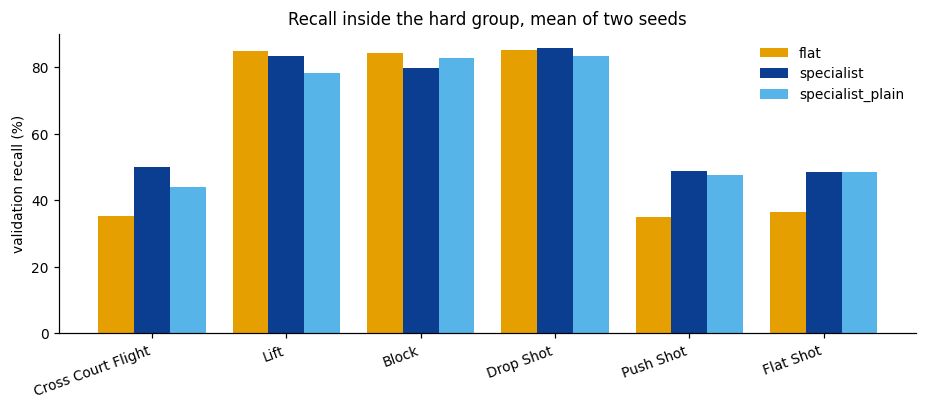

In [8]:
rec_cols = [f"rec_{n}" for n in GROUP_SHORT]
rec = rv.groupby("arm")[rec_cols].mean().reindex(ARM_ORDER).T
rec.index = GROUP_SHORT
rec["validation clips"] = [int((lab == k).sum()) for k in range(G)]
display((100 * rec.drop(columns="validation clips")).round(1).assign(**{"validation clips": rec["validation clips"]}))

colours = {"flat": "#E69F00", "specialist": "#0B3D91", "specialist_plain": "#56B4E9"}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
w = 0.8 / len(ARM_ORDER)
for j, a in enumerate(ARM_ORDER):
    ax.bar(np.arange(G) + (j - (len(ARM_ORDER) - 1) / 2) * w, 100 * rec[a], w, label=a, color=colours[a])
ax.set_xticks(range(G), GROUP_SHORT, rotation=20, ha="right")
ax.set_ylabel("validation recall (%)")
ax.set_title("Recall inside the hard group, mean of two seeds")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Save

The verdict is stored so the next notebook can check it before building anything.

In [9]:
summary = {"experiment": "hierarchy_specialist_test", "seeds": SEEDS, "splits_used": ["train", "val"], "group": GROUP_SHORT,
           "rule": {"min_gain_group_acc_pts": 100 * MIN_GAIN, "max_group_mca_drop_pts": 100 * MAX_MCA_DROP, "gain_in_every_seed": True,
                    "arm": "specialist (step matched schedule)"},
           "schedule_scale": SCALE, "sampler_draws": {"flat": flat_draws, "specialist": spec_draws},
           "group_acc_mean_pts": {a: round(100 * float(mean.loc[a, "group_acc"]), 2) for a in ARM_ORDER},
           "group_mca_mean_pts": {a: round(100 * float(mean.loc[a, "group_mca"]), 2) for a in ARM_ORDER},
           "flat_unrestricted_group_acc_pts": round(100 * float(mean.loc["flat", "group_acc_unrestricted"]), 2),
           "differences": diffs.to_dict(orient="records"), "passed": passed, "split_sha256": split_hash}
with open(f"{REPO}/configs/hierarchy_specialist.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

task = Task.init(project_name=PROJECT, task_name="specialist_test_summary", task_type=Task.TaskTypes.qc, tags=["hierarchy", "specialist_test", "summary"],
                 reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "seeds": SEEDS, "group": GROUP_SHORT, "schedule_scale": SCALE, "split_sha256": split_hash})
log.report_table("summary", "val", iteration=0, table_plot=show.reset_index().rename(columns={"index": "arm"}))
log.report_table("differences", "val", iteration=0, table_plot=diffs)
log.report_table("recall inside the group", "val", iteration=0, table_plot=(100 * rec.drop(columns="validation clips")).round(1).reset_index().rename(columns={"index": "class"}))
log.report_matplotlib_figure("group recall", "val", figure=fig, iteration=0, report_interactive=False)
log.report_single_value("rule passed", float(passed))
task.upload_artifact("summary", artifact_object=f"{REPO}/configs/hierarchy_specialist.json")
task.close()
print("saved configs/hierarchy_specialist.json | passed:", passed)

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=3a3d511f71df429facabb09eb77d4fe9
ClearML results page: https://app.clear.ml/projects/652cf33f95cb4ff8bc39ab6f47f9325f/tasks/3a3d511f71df429facabb09eb77d4fe9/output/log
saved configs/hierarchy_specialist.json | passed: True


In [10]:
# How much of the validation score is selection luck? Compare the selected epoch with its neighbours (3 epochs either side, itself excluded).
# The specialist is scored on exactly the clips its checkpoint was chosen on; flat is chosen on all 781 validation clips.
rows = []
for a in ARM_ORDER:
    for s in SEEDS:
        h = pd.read_csv(f"{OUT}/t40_{a}_s{s}/t40_{a}_s{s}_history.csv")
        b = int(h["val_composite"].idxmax())
        nb = h.loc[[i for i in range(max(0, b - 3), min(len(h), b + 4)) if i != b]]
        rows.append({"arm": a, "seed": s, "selected epoch": b, "val top1 at selected": 100 * h.loc[b, "val_top1"],
                     "val top1, 3 epochs either side": 100 * nb["val_top1"].mean(),
                     "val MCA at selected": 100 * h.loc[b, "val_mca"], "val MCA, 3 epochs either side": 100 * nb["val_mca"].mean()})
bias = pd.DataFrame(rows)
bias["top1 selection gain"] = bias["val top1 at selected"] - bias["val top1, 3 epochs either side"]
bias["MCA selection gain"] = bias["val MCA at selected"] - bias["val MCA, 3 epochs either side"]
display(bias.round(2))
display(bias.groupby("arm")[["top1 selection gain", "MCA selection gain"]].mean().round(2))

,arm,seed,selected epoch,val top1 at selected,"val top1, 3 epochs either side",val MCA at selected,"val MCA, 3 epochs either side",top1 selection gain,MCA selection gain
0,flat,77,21,79.51,78.98,70.00,68.78,0.53,1.22
1,flat,88,22,79.77,78.60,69.25,67.61,1.17,1.64
2,specialist,77,33,73.12,70.55,67.27,62.92,2.57,4.35
3,specialist,88,33,72.04,70.49,64.82,63.45,1.55,1.37
4,specialist_plain,77,26,71.33,70.37,64.52,62.39,0.96,2.13
5,specialist_plain,88,24,69.18,67.62,63.66,59.67,1.55,3.99


,top1 selection gain,MCA selection gain
arm,,
flat,0.85,1.43
specialist,2.06,2.86
specialist_plain,1.25,3.06
